<a href="https://colab.research.google.com/github/ToluwaniOladeji/Formative_3_Group_9/blob/main/formative3_group_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Formative 3: EM, Bayesian Probability & Gradient Descent

**Group:** _<group name>_  |  **Cohort:** _<1/2/3>_  |  **Presentation slot:** _<date/time>_

| Member | GitHub | Main parts | Also presents |
|---|---|---|---|
| Member A | `@garangbse` | Part 1 (EM code) | |
| Member B | `@username` | Part 1 (theory/plots), Part 2 | |
| Member C | `@username` | Parts 3 & 4 | |

**How to use this template**
- Search for `TODO` to find everything that needs filling in.
- Each part is owned by one person. Work on your own branch or copy and commit often under **your own name**.
- Keep code **modular and DRY**: functions with docstrings, no copy-pasted blocks.
- Add images/plots next to the explanations so the notebook works as a presentation.

**Contents**
1. [Part 1: EM Algorithm](#part-1)
2. [Part 2: Bayesian Probability](#part-2)
3. [Part 3: Gradient Descent (manual)](#part-3)
4. [Part 4: Gradient Descent (code)](#part-4)
5. [Contributions](#contributions)

## Setup (shared by all parts)

In [45]:
# TODO (everyone): imports and shared settings
import csv
import math
import random
import numpy
import matplotlib.pyplot as plt
# - Set a random seed for reproducibility
# - Define shared constants agreed by the group: HEIGHTS_PATH, IMDB_PATH, LEARNING_RATE, N_UPDATES (= number of members)

<a id="part-1"></a>
# Part 1: Probability Distributions (EM Algorithm)

**Owners:** _Member A (code)_, _Member B (theory & plots)_

**Chosen comparison:** _<Mothers vs Children  OR  Fathers vs Children>_  (TODO)

**Cluster labels:** _<which component is "Children", which is "Pros/Adults"? Explain how you decided.>_ (TODO)

### 1.1 Load and inspect the data

In [46]:
import pandas as pd

FILE_PATH = "GaltonFamilies.csv"

df = pd.read_csv(FILE_PATH)
df.head()

,rownames,family,father,mother,midparentHeight,children,childNum,gender,childHeight
0,1,001,78.5,67.0,75.43,4,1,male,73.2
1,2,001,78.5,67.0,75.43,4,2,female,69.2
2,3,001,78.5,67.0,75.43,4,3,female,69.0
3,4,001,78.5,67.0,75.43,4,4,female,69.0
4,5,002,75.5,66.5,73.66,4,1,male,73.5


Number of heights: 1139
Minimum height: 56.0
Maximum height: 79.0
Global mean: 67.20851624231783


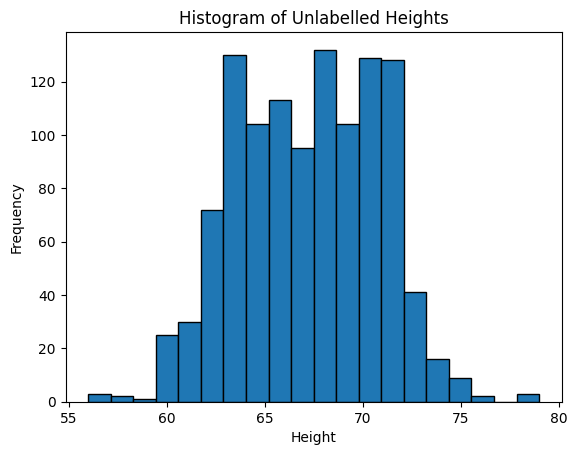

In [47]:
def load_data(filename):
    heights = []
    seen_families = set()

    with open(filename, "r") as file:
        reader = csv.DictReader(file)
        for row in reader:
            if row["family"] not in seen_families:
                heights.append(float(row["father"]))
                seen_families.add(row["family"])

            heights.append(float(row["childHeight"]))

    return heights


heights = load_data("GaltonFamilies.csv")

n = len(heights)
minimum = min(heights)
maximum = max(heights)
global_mean = sum(heights) / n

print("Number of heights:", n)
print("Minimum height:", minimum)
print("Maximum height:", maximum)
print("Global mean:", global_mean)

plt.hist(heights, bins=20, edgecolor="black")
plt.xlabel("Height")
plt.ylabel("Frequency")
plt.title("Histogram of Unlabelled Heights")
plt.show()

### 1.2 Gaussian Function

In [48]:
def gaussian(x, mean, variance):
    return (1 / math.sqrt(2 * math.pi * variance)) * math.exp(-((x - mean) ** 2) / (2 * variance))

### 1.3 EM from scratch

Model: $p(x) = \pi_1\,\mathcal{N}(x\mid\mu_1,\sigma_1^2) + \pi_2\,\mathcal{N}(x\mid\mu_2,\sigma_2^2)$

- **E-step:** responsibilities $\gamma_{ik} = \dfrac{\pi_k \mathcal{N}(x_i\mid\mu_k,\sigma_k^2)}{\sum_j \pi_j \mathcal{N}(x_i\mid\mu_j,\sigma_j^2)}$
- **M-step:** $N_k=\sum_i\gamma_{ik}$, $\;\mu_k=\frac{1}{N_k}\sum_i\gamma_{ik}x_i$, $\;\sigma_k^2=\frac{1}{N_k}\sum_i\gamma_{ik}(x_i-\mu_k)^2$, $\;\pi_k=\frac{N_k}{N}$
- **Stop** when the log-likelihood change is below a tolerance.

In [49]:
def log_likelihood(data, mean1, mean2, variance1, variance2, pi1, pi2):
    total = 0
    for x in data:
        value = pi1 * gaussian(x, mean1, variance1) + pi2 * gaussian(x, mean2, variance2)
        total += math.log(value)
    return total

# max iterations = 100
# tolerance = 1e-2
def EM(data, tolerance=1e-2, max_iterations=100):

    # INITIALIZATION
    n = len(data)
    average = sum(data) / n
    data_variance = sum((x - average) ** 2 for x in data) / n
    spread = math.sqrt(data_variance)      # standard deviation of the data

    mean1 = average - spread
    mean2 = average + spread

    variance1 = data_variance
    variance2 = data_variance

    pi1 = 0.5
    pi2 = 0.5

    # initial log-likelihood (before any update)
    log_lik = log_likelihood(data, mean1, mean2, variance1, variance2, pi1, pi2)

    # history of every iteration, starting with iteration 0
    history = [(0, mean1, mean2, variance1, variance2, pi1, pi2, log_lik)]

    iteration = 0
    while iteration < max_iterations:
        iteration += 1

        responsibilities1 = []
        responsibilities2 = []

        # E STEP
        for x in data:
            prob1 = pi1 * gaussian(x, mean1, variance1)
            prob2 = pi2 * gaussian(x, mean2, variance2)
            total = prob1 + prob2

            responsibilities1.append(prob1 / total)
            responsibilities2.append(prob2 / total)

        # M STEP
        N1 = sum(responsibilities1)
        N2 = sum(responsibilities2)

        mean1 = sum(responsibilities1[i] * data[i] for i in range(n)) / N1
        mean2 = sum(responsibilities2[i] * data[i] for i in range(n)) / N2

        variance1 = sum(responsibilities1[i] * (data[i] - mean1) ** 2 for i in range(n)) / N1
        variance2 = sum(responsibilities2[i] * (data[i] - mean2) ** 2 for i in range(n)) / N2

        pi1 = N1 / n
        pi2 = N2 / n

        # new log-likelihood
        new_log_lik = log_likelihood(data, mean1, mean2, variance1, variance2, pi1, pi2)
        history.append((iteration, mean1, mean2, variance1, variance2, pi1, pi2, new_log_lik))

        # convergence check: stop when the log-likelihood barely changes
        if abs(new_log_lik - log_lik) < tolerance:
            break
        log_lik = new_log_lik

    return (mean1, mean2, variance1, variance2, pi1, pi2), history

### 1.4 Tracking table

In [50]:
def print_row(row):
    it, m1, m2, v1, v2, p1, p2, ll = row
    label = f"{it} (Init)" if it == 0 else str(it)
    print(f"{label:>10} | {m1:8.4f} | {m2:8.4f} | {v1:8.4f} | {v2:8.4f} | {p1:6.4f} | {p2:6.4f} | {ll:12.4f}")

def print_table(history):
    print(f"{'Iteration':>10} | {'mu1':>8} | {'mu2':>8} | {'var1':>8} | {'var2':>8} | {'pi1':>6} | {'pi2':>6} | {'LogLikelihood':>12}")
    print("-" * 94)
    for row in history[:5]:             # iterations 0:5
        print_row(row)
    if len(history) > 5:
        print(f"{'...':>10}")
        print_row(history[-1])  # final (converged) iteration

## 1.5 Prediction Step


In [51]:
def log_weighted_gaussian(x, mean, variance, pi):
    # log( pi * N(x | mean, variance) ) written directly in log form
    return math.log(pi) - 0.5 * math.log(2 * math.pi * variance) - ((x - mean) ** 2) / (2 * variance)


def predict(height, model):

    mean1, mean2, var1, var2, pi1, pi2 = model

    # the group with the smaller mean is the Child group (fathers are taller on average)
    if mean1 < mean2:
        child_mean, child_var, child_pi = mean1, var1, pi1
        father_mean, father_var, father_pi = mean2, var2, pi2
    else:
        child_mean, child_var, child_pi = mean2, var2, pi2
        father_mean, father_var, father_pi = mean1, var1, pi1

    log_child = log_weighted_gaussian(height, child_mean, child_var, child_pi)
    log_father = log_weighted_gaussian(height, father_mean, father_var, father_pi)

    # log-sum-exp: subtract the larger log value so exp() never underflows to 0
    biggest = max(log_child, log_father)
    child_exp = math.exp(log_child - biggest)
    father_exp = math.exp(log_father - biggest)
    total = child_exp + father_exp

    child_probability = child_exp / total
    father_probability = father_exp / total

    print("\nPrediction for:", height)
    print("Probability it is a Child :", round(child_probability, 6), f"({child_probability * 100:.2f} %)")
    print("Probability it is a Father:", round(father_probability, 6), f"({father_probability * 100:.2f} %)")
    print("Sum of probabilities      :", round(child_probability + father_probability, 6))
    print("Decision ->", "Child" if child_probability > father_probability else "Father")

## 1.6 Run the Model

In [52]:
data = load_data(FILE_PATH)
model, history = EM(data)

print("Number of heights:", len(data))
print("Converged after", history[-1][0], "iterations\n")
print_table(history)

mean1, mean2, var1, var2, pi1, pi2 = model
print("\nFinal model")
print(f"Group 1: mean={mean1:.3f}, std={math.sqrt(var1):.3f}, pi={pi1:.3f}")
print(f"Group 2: mean={mean2:.3f}, std={math.sqrt(var2):.3f}, pi={pi2:.3f}")

Number of heights: 1139
Converged after 19 iterations

 Iteration |      mu1 |      mu2 |     var1 |     var2 |    pi1 |    pi2 | LogLikelihood
----------------------------------------------------------------------------------------------
  0 (Init) |  63.6414 |  70.7756 |  12.7241 |  12.7241 | 0.5000 | 0.5000 |   -3194.5755
         1 |  64.9339 |  69.4553 |   7.9124 |   7.3183 | 0.4969 | 0.5031 |   -3053.3088
         2 |  64.8745 |  69.5053 |   7.7363 |   6.9965 | 0.4960 | 0.5040 |   -3052.1871
         3 |  64.8207 |  69.5548 |   7.5033 |   6.7466 | 0.4956 | 0.5044 |   -3051.1676
         4 |  64.7715 |  69.6005 |   7.2673 |   6.5289 | 0.4953 | 0.5047 |   -3050.2528
       ...
        19 |  64.4813 |  69.7771 |   5.9158 |   5.5336 | 0.4850 | 0.5150 |   -3047.2561

Final model
Group 1: mean=64.481, std=2.432, pi=0.485
Group 2: mean=69.777, std=2.352, pi=0.515


## 1.7 Classify a Test Height

In [53]:
try:
    test_height = float(input("Enter test height: "))
except Exception:                      # no keyboard input available (e.g. running all cells automatically)
    test_height = 67.0
    print("No input available, using default test height 67.0")

predict(test_height, model)

Enter test height: 75

Prediction for: 75.0
Probability it is a Child : 0.000929 (0.09 %)
Probability it is a Father: 0.999071 (99.91 %)
Sum of probabilities      : 1.0
Decision -> Father


### 1.8 Visualisations

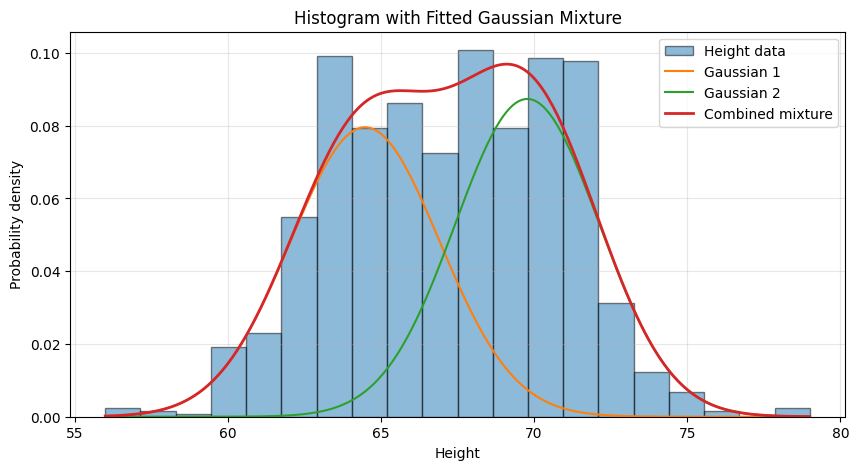

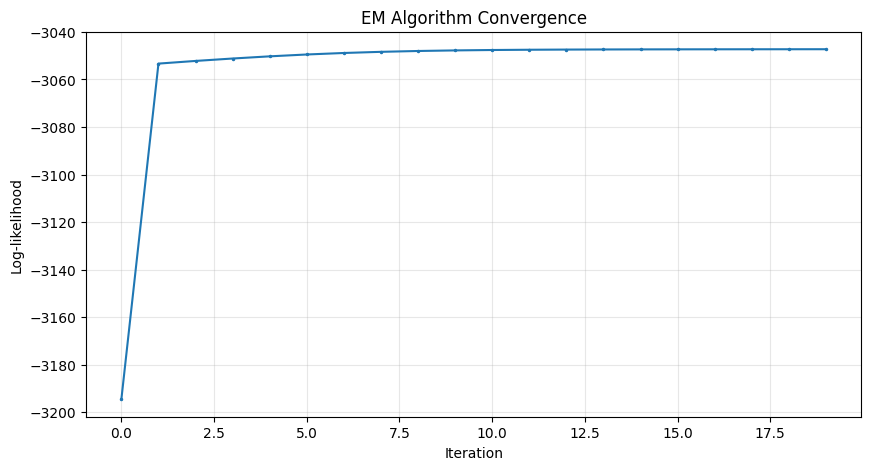

In [54]:
# Extract fitted parameters
mean1, mean2, var1, var2, pi1, pi2 = model

# Create x-values for the Gaussian curves
x_values = [min(data) + i * (max(data) - min(data)) / 299 for i in range(300)]

# Plot 1: Histogram and fitted Gaussian mixture
plt.figure(figsize=(10, 5))
plt.hist(data, bins=20, density=True, alpha=0.5, edgecolor="black", label="Height data")

curve1 = [pi1 * gaussian(x, mean1, var1) for x in x_values]
curve2 = [pi2 * gaussian(x, mean2, var2) for x in x_values]
mixture = [y1 + y2 for y1, y2 in zip(curve1, curve2)]

plt.plot(x_values, curve1, label="Gaussian 1")
plt.plot(x_values, curve2, label="Gaussian 2")
plt.plot(x_values, mixture, label="Combined mixture", linewidth=2)
plt.xlabel("Height")
plt.ylabel("Probability density")
plt.title("Histogram with Fitted Gaussian Mixture")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Plot 2: Log-likelihood vs iteration
iterations = [row[0] for row in history]
log_likelihoods = [row[7] for row in history]

plt.figure(figsize=(10, 5))
plt.plot(iterations, log_likelihoods, marker=".", markersize=3)
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.title("EM Algorithm Convergence")
plt.grid(alpha=0.3)
plt.show()


<a id="part-2"></a>
# Part 2: Bayesian Probability (IMDb Reviews)

**Owner:** _Member B_  |  **Rule:** basic Python only (no ML libraries; `csv`, `math`, `collections` are fine)

**Conditional chosen (pick ONE):** `P(Positive | keyword)`  _or_  `P(Negative | keyword)` (TODO, do not compute both)

**Keywords and justification (TODO):**

| Keyword | Expected sentiment | Why we chose it |
|---|---|---|
| | positive | |
| | positive | |
| | negative | |
| | negative | |

In [55]:
import csv
import re
import sys


In [56]:
POSITIVE_KEYWORDS = ["excellent", "wonderful", "amazing", "great"]
NEGATIVE_KEYWORDS = ["terrible", "awful", "waste", "boring"]
KEYWORDS = POSITIVE_KEYWORDS + NEGATIVE_KEYWORDS

In [57]:
def tokenize(text):
    """Lowercase the review, drop HTML line breaks, return the set of words."""
    text = text.lower().replace("<br />", " ")
    return set(re.findall(r"[a-z']+", text))


def bayes_posterior(prior, likelihood, marginal):
    """Bayes' theorem: P(Pos|kw) = P(kw|Pos) * P(Pos) / P(kw)."""
    if marginal == 0:
        return 0.0
    return likelihood * prior / marginal

In [58]:
DATASET_PATH = "IMDB Dataset.csv"   # change if your file has a different name or location

total = 0
positive_total = 0
kw_in_all = {k: 0 for k in KEYWORDS}   # reviews containing the keyword
kw_in_pos = {k: 0 for k in KEYWORDS}   # positive reviews containing the keyword

with open(DATASET_PATH, encoding="utf-8", newline="") as f:
    reader = csv.DictReader(f)
    for row in reader:
        words = tokenize(row["review"])
        is_positive = row["sentiment"].strip().lower() == "positive"
        total += 1
        if is_positive:
            positive_total += 1
        for k in KEYWORDS:
            if k in words:
                kw_in_all[k] += 1
                if is_positive:
                    kw_in_pos[k] += 1

print("Total reviews:", total)
print("Positive reviews:", positive_total)

FileNotFoundError: [Errno 2] No such file or directory: 'IMDB Dataset.csv'

In [ ]:
prior = positive_total / total
print(f"Prior P(Positive) = {positive_total}/{total} = {prior:.4f}")

In [ ]:
print("| Keyword | Prior P(Pos) | Likelihood P(kw|Pos) | Marginal P(kw) | Posterior P(Pos|kw) |")
print("|---|---|---|---|---|")
for k in KEYWORDS:
    likelihood = kw_in_pos[k] / positive_total      # P(kw | Positive)
    marginal = kw_in_all[k] / total                 # P(kw)
    posterior = bayes_posterior(prior, likelihood, marginal)
    print(f"| {k} | {prior:.4f} | {likelihood:.4f} | {marginal:.4f} | {posterior:.4f} |")

In [ ]:
for k in KEYWORDS:
    direct = kw_in_pos[k] / kw_in_all[k] if kw_in_all[k] else 0.0
    print(f"{k}: {kw_in_pos[k]}/{kw_in_all[k]} = {direct:.4f}")

In [ ]:
# TODO (Member B): load the reviews and print the results table for all chosen keywords

**Interpretation (TODO):** _Which keywords are strong indicators? Did any surprise us? Why (sarcasm, negation, rare words)?_

<a id="part-3"></a>
# Part 3: Gradient Descent, Manual Calculation

**Owners:** one update each (Update 1: Member A, Update 2: Member B, Update 3: Member C). Derivation: Member C.

The full handwritten work goes in the separate PDF. This section records the setup, the derivation summary, and a **numerical check** of each handwritten update.

### Model (TODO: confirm the "X" with the instructor)
$$\hat{y} = X\,m + b,\qquad X=\begin{bmatrix}1&3\\4&10\end{bmatrix},\; m=\begin{bmatrix}-1\\2\end{bmatrix},\; b=\begin{bmatrix}1\\1\end{bmatrix},\; y=\begin{bmatrix}5\\6\end{bmatrix}$$

### Cost
$$J(m,b)=\frac{1}{N}\sum_{i=1}^{N}(\hat{y}_i-y_i)^2 = \frac{1}{N}(\hat y-y)^\top(\hat y-y)$$

### Derivation with the chain rule (TODO: write every step)
Let $e=\hat y-y$. Then
- $\dfrac{\partial J}{\partial m}=\dfrac{\partial J}{\partial e}\dfrac{\partial e}{\partial m}=\;$ _TODO_
- $\dfrac{\partial J}{\partial b}=\dfrac{\partial J}{\partial e}\dfrac{\partial e}{\partial b}=\;$ _TODO_

**Decisions to state clearly (also used in Part 4):**
- Learning rate $\alpha$ = _TODO_
- Treatment of $b$'s gradient (element-wise vector vs summed scalar) = _TODO_

In [ ]:
# TODO (Member C): numerical check of the handwritten work
# - Define X, y, initial m, and initial b as column vectors (numpy arrays)
# - Write a predict function using matrix multiplication (X @ m + b)
# - Print the initial predictions
# - Later: compare each handwritten update (1, 2, 3) with the values computed here

### Update table (fill in from the handwritten PDF, then confirm with Part 4 code)

| Update | Done by | $\hat y$ | $J$ | $\partial J/\partial m$ | $\partial J/\partial b$ | new $m$ | new $b$ |
|---|---|---|---|---|---|---|---|
| 1 | Member A | | | | | | |
| 2 | Member B | | | | | | |
| 3 | Member C | | | | | | |

**Observed trend (TODO):** _Are $m$ and $b$ moving in a direction that reduces the error? Show the cost value after each update._

<a id="part-4"></a>
# Part 4: Gradient Descent in Code

**Owner:** _Member C_ (everyone reviews)

Requirements: SciPy derivative function, visible update steps, plot of $m$ and $b$ over iterations, separate plot of error over iterations.

In [ ]:
# TODO (Member C): SciPy derivative function
# - Print the SciPy version
# - Import the derivative function (scipy.differentiate.derivative in new versions, scipy.misc.derivative in old ones)
# - Write a function that accepts an equation (a Python function) and returns its derivative at a point using SciPy

In [ ]:
# TODO (Member C): gradient descent building blocks (keep each calculation step visible)
# - mse: mean squared error
# - gradients: dJ/dm and dJ/db using the matrix formulas from Part 3 (show y_hat and the error as separate steps)
# - gradient_descent_step: update m and b once and return the new values plus the cost
# - run_gradient_descent: loop for n iterations, store m, b, and cost at every step, print intermediate values for the first updates

In [ ]:
# TODO (Member C): run and compare
# - Run N_UPDATES iterations and compare with the handwritten Part 3 results
# - Run a longer run (e.g. 200 iterations) to see the trend
# - Compute and print predictions with the final m and b

In [ ]:
# TODO (Member C): Matplotlib plots
# - Plot 1: m1, m2, and b over iterations
# - Plot 2 (separate figure): error (cost) over iterations

**Discussion (TODO):** _Does the error decrease every iteration? What happens with a larger learning rate? Do the code results match the handwritten numbers?_

<a id="contributions"></a>
# Contributions

Each member fills in their own row, then export a **separate PDF** of this section with links to commits.

| Member | Parts / files worked on | Key commits (links) | Presents which sections |
|---|---|---|---|
| Member A | | | |
| Member B | | | |
| Member C | | | |

### Pre-submission checklist
- [ ] Every member has commits in the GitHub repo
- [ ] All `TODO` markers removed
- [ ] Code is modular and DRY (no repeated blocks)
- [ ] Part 2 uses basic Python only
- [ ] Tracking table, test-height posterior, and both Part 4 plots render
- [ ] Handwritten Part 3 PDF scanned and neat
- [ ] README written as a presentation guide
- [ ] Contributions PDF exported
- [ ] Everyone knows when they speak; 15-minute rehearsal done